image grid 25 x 25 x 71, 357043 scatterer candidates (2.7-9.3 km deep)


C:\Users\julia\AppData\Local\Temp\ipykernel_51252\1096994057.py:289: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(data, vert=False, widths=0.5)
C:\Users\julia\AppData\Local\Temp\ipykernel_51252\1096994057.py:289: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(data, vert=False, widths=0.5)
C:\Users\julia\AppData\Local\Temp\ipykernel_51252\1096994057.py:289: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(data, vert=False, widths=0.5)


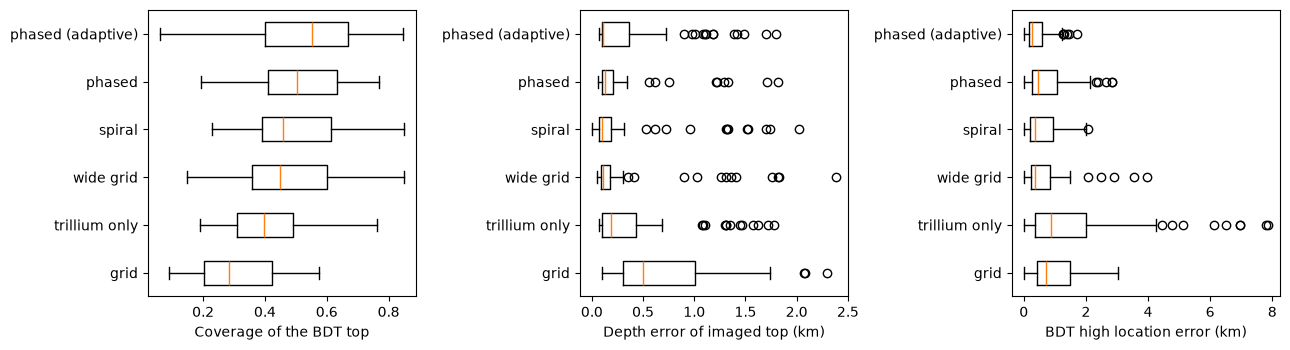

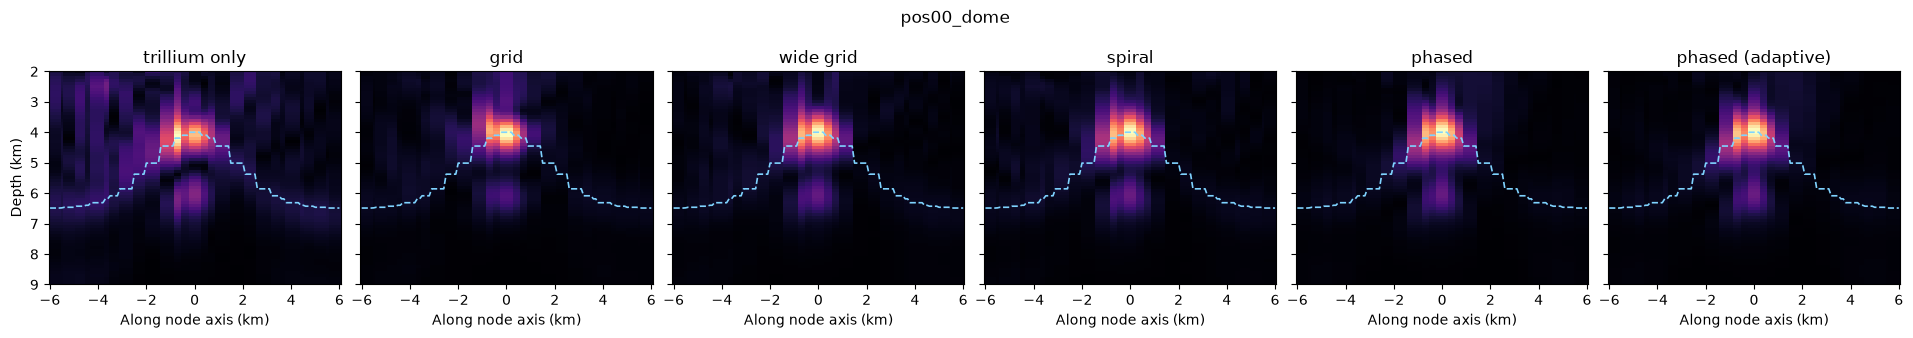

In [2]:
# --- Imports ---
import json
import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# %%
# --- Settings ---
DATA = "../data"
SCENARIOS = None                  # None = all, or a list such as ["pos00_dome", "pos03_block"]
DESIGNS = None                    # None = all in designs.json plus "phased (adaptive)"
PHASE = "p"                       # "p" or "s" (needs the S tables from 03)

DF = 0.1 if PHASE == "p" else 0.05    # Hz. small enough that two-way times (P < ~8 s, S < ~14 s) do not wrap
F = np.arange(1.0, 6.0 + 1e-9, DF)
WF = np.hanning(len(F) + 2)[1:-1]     # source spectrum: Hann taper over the band

DROP_VP, VS_RATIO, EDGE = 0.05, 2.0, 0.3   # LVZ: Vp drop, Vs drop / Vp drop, edge ramp (km). Keep in step with 04
DROP = DROP_VP if PHASE == "p" else VS_RATIO * DROP_VP   # drop in the velocity this run images with
BOX, BOX_TAPER = 9.0, 2.0         # scatterers within +-BOX km of the drill site, tapered over the last BOX_TAPER km
SC_STEP = (1, 1, 1)               # scatterer grid = travel-time grid every (nx, ny, nz) nodes (0.25, 0.25, 0.1 km)
IM_R, IM_Z = 6.0, (2.0, 9.0)      # image within +-IM_R km of the drill site, IM_Z km deep
IM_STEP = (2, 2, 1)               # image grid = travel-time grid every (nx, ny, nz) nodes (0.5, 0.5, 0.1 km)

TARGET_R = 3.0                    # km: columns this close to the conductor centre count as the target
SNR_MIN = 3.0                     # a column is imaged if its peak is this many times the image's median (background)
CREST_FRAC = 0.5                  # the BDT high is picked only from columns at least this bright relative to the brightest
TOP_TOL = 0.3                     # km: an imaged column covers the top if its picked top is within this of the truth
P2_SEARCH_R = 4.0                 # km: phase 2 centre is kept this close to the planned centre (as in 02)

RESULTS = f"{DATA}/results_05_mi{'' if PHASE == 'p' else '_s'}.csv"
IMAGE_DIR = f"{DATA}/mi_images{'' if PHASE == 'p' else '_s'}"

# %%
# --- Inputs ---
vm = np.load(f"{DATA}/velocity_model.npz")
vx, vy, vz, vp = vm["x"], vm["y"], vm["z"], vm["vp"] if PHASE == "p" else vm["vs"]
stations = pd.read_csv(f"{DATA}/stations.csv", index_col="station")
D = json.load(open(f"{DATA}/designs.json"))
sc_npz = np.load(f"{DATA}/scenarios.npz")
SC = json.load(open(f"{DATA}/scenarios.json"))
tg = np.load(f"{DATA}/tt/grid.npz")
tx, ty, tz = tg["x"], tg["y"], tg["z"]

# travel-time grid -> velocity-model grid indices (the tt grid is a crop of the model grid)
mx, my, mz = (np.searchsorted(np.round(a, 6), np.round(b, 6)) for a, b in ((vx, tx), (vy, ty), (vz, tz)))
assert np.allclose(vx[mx], tx) and np.allclose(vy[my], ty) and np.allclose(vz[mz], tz)


def nodes(xr, zr, step):
    """Travel-time-grid node indices within +-xr km horizontally and zr depth, every step nodes."""
    i = np.where(np.abs(tx) <= xr + 1e-9)[0][::step[0]]
    j = np.where(np.abs(ty) <= xr + 1e-9)[0][::step[1]]
    k = np.where((tz >= zr[0] - 1e-9) & (tz <= zr[1] + 1e-9))[0][::step[2]]
    return i, j, k


# scatterer candidates (kept per scenario only where the LVZ perturbation is non-zero)
SC_Z = (np.nanmin([sc_npz[k] for k in sc_npz.files if k.startswith("top_")]) - EDGE,
        np.nanmax([sc_npz[k] for k in sc_npz.files if k.startswith("base_")]) + EDGE)   # depths any LVZ reaches
si, sj, sk = nodes(BOX, SC_Z, SC_STEP)
SI, SJ, SK = (a.ravel() for a in np.meshgrid(si, sj, sk, indexing="ij"))
edge = np.clip((BOX - np.maximum(np.abs(tx[SI]), np.abs(ty[SJ]))) / BOX_TAPER, 0, 1)
SC_TAPER = 0.5 - 0.5 * np.cos(np.pi * edge)
CELL = (tx[1] - tx[0]) * SC_STEP[0] * (ty[1] - ty[0]) * SC_STEP[1] * (tz[1] - tz[0]) * SC_STEP[2]

# image grid
ii, ij, ik = nodes(IM_R, IM_Z, IM_STEP)
IX, IY, IZ = tx[ii], ty[ij], tz[ik]
II, IJ, IK = (a.ravel() for a in np.meshgrid(ii, ij, ik, indexing="ij"))
print(f"image grid {len(ii)} x {len(ij)} x {len(ik)}, {len(SI)} scatterer candidates "
      f"({SC_Z[0]:.1f}-{SC_Z[1]:.1f} km deep)")

# %%
# --- Scenario perturbation: the LVZ of 04 as Born scatterers ---
def perturbation(name):
    """Scatterer nodes (indices into SI/SJ/SK) and strengths sigma = d(1/v^2) x cell volume x edge taper."""
    top = sc_npz[f"top_{name}"][mx[SI], my[SJ]]
    base = sc_npz[f"base_{name}"][mx[SI], my[SJ]]
    zz = tz[SK]
    w = np.clip(np.minimum(zz - np.nan_to_num(top, nan=99), np.nan_to_num(base, nan=99) - zz) / EDGE + 0.5, 0, 1)
    v0 = vp[mx[SI], my[SJ], mz[SK]]
    sig = (1 / (v0 * (1 - DROP * w)) ** 2 - 1 / v0 ** 2) * CELL * SC_TAPER
    keep = np.abs(sig) > 1e-6 * np.abs(sig).max()
    return np.where(keep)[0], sig[keep].astype(np.float32)


# --- Travel times and spreading from each station, read from the 03 tables ---
_tt = {}


def station_tt(s):
    """(travel times to all scatterer candidates, travel times to all image nodes) for station s."""
    if s not in _tt:
        t = np.load(f"{DATA}/tt/{s:03d}_{PHASE}.npy", mmap_mode="r")
        _tt[s] = (np.asarray(t[SI, SJ, SK]), np.asarray(t[II, IJ, IK]))          # float16, as stored
    return _tt[s]


def spreading(s, x, y, z):
    r = np.sqrt((x - stations.x[s]) ** 2 + (y - stations.y[s]) ** 2 + z ** 2)
    return (1 / (4 * np.pi * np.maximum(r, 0.05))).astype(np.float32)

# %%
# --- Forward model and confocal image ---
def forward(ids, k_sc, sig):
    """Reflection matrices R(f) between stations ids, for the scatterers k_sc with strengths sig. (nF, N, N)"""
    T = np.stack([station_tt(s)[0][k_sc] for s in ids]).astype(np.float32)
    A = np.stack([spreading(s, tx[SI[k_sc]], ty[SJ[k_sc]], tz[SK[k_sc]]) for s in ids])
    R = np.empty((len(F), len(ids), len(ids)), np.complex64)
    for n, f in enumerate(F):
        G = A * np.exp(-2j * np.pi * f * T)                      # G(k, s_i), (N, K)
        R[n] = (G * sig) @ G.T
    return R


def image(ids, R, pair_mask):
    """Confocal image I(x) = |sum_f W(f) sum_ij G*(x, s_i) R_ij G*(s_j, x)| on the image grid."""
    T = np.stack([station_tt(s)[1] for s in ids]).T.astype(np.float32)   # (P, N)
    A = np.stack([spreading(s, tx[II], ty[IJ], tz[IK]) for s in ids]).T
    I = np.zeros(len(II), np.complex128)
    for n, f in enumerate(F):
        Gc = A * np.exp(2j * np.pi * f * T)
        I += WF[n] * np.einsum("pi,ij,pj->p", Gc, R[n] * pair_mask, Gc, optimize=True)
    return np.abs(I).reshape(len(ii), len(ij), len(ik)).astype(np.float32)


# --- Who records with whom ---
DEPLOY_END = max(p["end"] for ph in D["designs"].values() for p in ph)
PERMANENT = D["trillium"] + D.get("existing", [])


def windows(phases):
    """Recording windows per station: permanent stations all deployment, nodes their own phase."""
    w = {s: [(0, DEPLOY_END)] for s in PERMANENT}
    for p in phases:
        for s in p["stations"]:
            w.setdefault(s, []).append((p["start"], p["end"]))
    return w


def pair_mask(ids, win):
    """True where stations i != j record at the same time."""
    M = np.zeros((len(ids), len(ids)), bool)
    for a, s in enumerate(ids):
        for b in range(a + 1, len(ids)):
            M[a, b] = M[b, a] = any(min(e1, e2) > max(s1, s2) for s1, e1 in win[s] for s2, e2 in win[ids[b]])
    return M

# %%
# --- Scores ---
def pick_top(img, min_peak=None):
    """Picked BDT top per image column: shallowest local maximum above half the column peak. NaN if not imaged."""
    peak = img.max(axis=2)
    imaged = peak >= (SNR_MIN * np.median(img) if min_peak is None else min_peak)
    a = img / np.maximum(peak[..., None], 1e-30)
    local = np.zeros_like(a, bool)
    local[..., 1:-1] = (a[..., 1:-1] >= a[..., :-2]) & (a[..., 1:-1] >= a[..., 2:]) & (a[..., 1:-1] >= 0.5)
    first = np.argmax(local, axis=2)
    top = np.where(imaged & local.any(axis=2), IZ[first], np.nan)
    return top


def crest(top, XX, YY, tol=0.1):
    """BDT high: centroid of the columns within tol km of the shallowest top (a plateau for flat-topped shapes)."""
    hi = np.isfinite(top) & (top <= np.nanmin(top) + tol)
    return np.array([XX[hi].mean(), YY[hi].mean()])


def score(img, name):
    """Coverage of the BDT top, depth error, and how far the picked BDT high is from the true one."""
    centre = np.array(SC["scenarios"][name]["centre"])
    true = sc_npz[f"top_{name}"][np.ix_(mx[ii], my[ij])]
    est = pick_top(img)
    XX, YY = np.meshgrid(IX, IY, indexing="ij")
    target = (np.hypot(XX - centre[0], YY - centre[1]) <= TARGET_R) & np.isfinite(true)
    err = np.abs(est - true)
    good = target & (err <= TOP_TOL)
    crest_true = crest(true, XX, YY)
    strong = pick_top(img, CREST_FRAC * img.max())
    if np.isfinite(strong).any():
        crest_est = crest(strong, XX, YY)
        crest_err = float(np.hypot(*(crest_est - crest_true)))
    else:
        crest_est, crest_err = np.array([np.nan, np.nan]), np.nan
    return dict(coverage=good.sum() / max(target.sum(), 1),
                top_err_km=float(np.nanmedian(err[target & np.isfinite(est)])) if (target & np.isfinite(est)).any()
                else np.nan,
                crest_err_km=crest_err, crest_x=crest_est[0], crest_y=crest_est[1])

# %%
# --- Adaptive phase 2: centre the rolling patches on the BDT high picked from the phase 1 image ---
P2 = D["p2"]
AZR = np.radians(P2["az"])
BANK = {(i, j): s for s, i, j in zip(D["bank"]["ids"], D["bank"]["i"], D["bank"]["j"])}


def adaptive_phase2(crest_xy):
    """Phase 2 patches (15 x 8 bank sites, cut into 5 x 4 patches in the planned order) around crest_xy."""
    c0 = np.array(P2["centre0"])
    d = np.asarray(crest_xy) - c0
    if np.hypot(*d) > P2_SEARCH_R:
        d *= P2_SEARCH_R / np.hypot(*d)
    along = d[0] * np.sin(AZR) + d[1] * np.cos(AZR)
    across = -d[0] * np.cos(AZR) + d[1] * np.sin(AZR)
    i0 = int(round(along / P2["spacing"])) - 7
    j0 = int(round(across / P2["spacing"] - 0.5)) - 3
    phases = []
    for q, (pi, pj) in enumerate(P2["order"]):
        ids = [BANK[(i0 + 5 * pi + a, j0 + 4 * pj + b)] for a in range(5) for b in range(4)
               if (i0 + 5 * pi + a, j0 + 4 * pj + b) in BANK]
        t0 = P2["p1_days"] + q * P2["patch_days"]
        phases.append(dict(start=t0, end=t0 + P2["patch_days"], stations=ids))
    return phases, c0 + d

# %%
# --- Run: every scenario x every design. Rerunning skips pairs already in the results file ---
designs = {k: v for k, v in D["designs"].items() if DESIGNS is None or k in DESIGNS}
run_adaptive = (DESIGNS is None or "phased (adaptive)" in DESIGNS) and "phased" in D["designs"]
names = list(SC["scenarios"]) if SCENARIOS is None else SCENARIOS
os.makedirs(IMAGE_DIR, exist_ok=True)
done = pd.read_csv(RESULTS) if os.path.exists(RESULTS) else pd.DataFrame(columns=["scenario", "design"])
wanted = list(designs) + (["phased (adaptive)"] if run_adaptive else [])

for name in names:
    todo = [d for d in wanted if not ((done.scenario == name) & (done.design == d)).any()]
    if not todo:
        continue
    t0 = time.time()
    k_sc, sig = perturbation(name)
    static = [d for d in todo if d != "phased (adaptive)"]
    need = sorted(set(PERMANENT) | {s for d in static for p in designs[d] for s in p["stations"]}
                  | ({s for s in D["designs"]["phased"][0]["stations"]} if "phased (adaptive)" in todo else set()))
    R = forward(need, k_sc, sig)
    pos = {s: n for n, s in enumerate(need)}
    rows, imgs = [], {}

    def run(design, phases, Rsub, ids, extra=None):
        win = windows(phases)
        M = pair_mask(ids, win)
        img = image(ids, Rsub, M)
        imgs[design] = img
        rows.append(dict(scenario=name, conductor=SC["scenarios"][name]["conductor"],
                         shape=SC["scenarios"][name]["shape"], design=design, n_stations=len(ids),
                         n_pairs=int(M.sum() // 2), **score(img, name), **(extra or {})))
        return img

    for d in static:
        ids = sorted(set(PERMANENT) | {s for p in designs[d] for s in p["stations"]})
        sel = [pos[s] for s in ids]
        run(d, designs[d], R[:, sel][:, :, sel], ids)

    if "phased (adaptive)" in todo:
        p1 = D["designs"]["phased"][0]
        ids1 = sorted(set(PERMANENT) | set(p1["stations"]))
        sel = [pos[s] for s in ids1]
        pick = score(run("phased: phase 1 only", [p1], R[:, sel][:, :, sel], ids1), name)
        rows.pop()                                       # phase 1 alone is not a design; keep only its pick
        xy = (pick["crest_x"], pick["crest_y"]) if np.isfinite(pick["crest_x"]) else P2["centre0"]
        p2_phases, centre = adaptive_phase2(xy)
        phases = [p1] + p2_phases
        ids = sorted(set(PERMANENT) | {s for p in phases for s in p["stations"]})
        run("phased (adaptive)", phases, forward(ids, k_sc, sig), ids,
            extra=dict(p2_centre_x=centre[0], p2_centre_y=centre[1]))
        imgs.pop("phased: phase 1 only", None)

    done = pd.concat([done, pd.DataFrame(rows)], ignore_index=True)
    done.to_csv(RESULTS, index=False)
    np.savez_compressed(f"{IMAGE_DIR}/{name}.npz", x=IX, y=IY, z=IZ, **{k.replace(" ", "_"): v for k, v in imgs.items()})
    print(f"{name}: {', '.join(todo)} in {time.time() - t0:.0f} s", flush=True)

# %%
# --- Summary: mean scores per design over the scenarios run ---
res = pd.read_csv(RESULTS)
summary = res.groupby("design")[["coverage", "top_err_km", "crest_err_km", "n_stations", "n_pairs"]].mean()
summary.sort_values("coverage", ascending=False).round(3)

# %%
# --- Scores per design ---
with plt.style.context("default"):
    fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
    order = summary.sort_values("coverage").index
    for ax, col, lab in zip(axs, ["coverage", "top_err_km", "crest_err_km"],
                            ["Coverage of the BDT top", "Depth error of imaged top (km)", "BDT high location error (km)"]):
        data = [res.loc[res.design == d, col].dropna() for d in order]
        ax.boxplot(data, vert=False, widths=0.5)
        ax.set_yticks(range(1, len(order) + 1), order)
        ax.set_xlabel(lab)
    plt.tight_layout()
    plt.show()

# %%
# --- Images for one scenario: section along the node axis through the conductor ---
SHOW = names[0]
im = np.load(f"{IMAGE_DIR}/{SHOW}.npz")
keys = [k for k in im.files if k not in ("x", "y", "z")]
centre = SC["scenarios"][SHOW]["centre"]
s = np.linspace(-6, 6, 121)
px, py = centre[0] + s * np.sin(AZR), centre[1] + s * np.cos(AZR)
jx = np.clip(np.round((px - im["x"][0]) / (im["x"][1] - im["x"][0])).astype(int), 0, len(im["x"]) - 1)
jy = np.clip(np.round((py - im["y"][0]) / (im["y"][1] - im["y"][0])).astype(int), 0, len(im["y"]) - 1)
true = sc_npz[f"top_{SHOW}"][np.searchsorted(vx, im["x"][jx]), np.searchsorted(vy, im["y"][jy])]

with plt.style.context("default"):
    fig, axs = plt.subplots(1, len(keys), figsize=(3.2 * len(keys), 3.4), sharey=True)
    for ax, k in zip(np.atleast_1d(axs), keys):
        sec = im[k][jx, jy, :]
        ax.pcolormesh(s, im["z"], (sec / sec.max()).T, cmap="magma", shading="auto", vmin=0, vmax=1)
        ax.plot(s, true, color="#7fd3ff", ls="--", lw=1.2)
        ax.set(title=k.replace("_", " "), ylim=(im["z"][-1], im["z"][0]), xlabel="Along node axis (km)")
    np.atleast_1d(axs)[0].set_ylabel("Depth (km)")
    fig.suptitle(SHOW)
    plt.tight_layout()
    plt.show()